# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Токарик Сергій'
LIST_NUMBER  = 7

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 7, файл lr6_варіант_07.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'
# чому: ціль «відтік» бінарна (1 — розірвав договір, 0 — лишився), а треба оцінити ризик для кожного клієнта.

METRIC = 'AUC'
# чому саме ця, а не точність: відтік складає менше третини клієнтів, тому модель «ніхто не піде»
# вже має точність ~71 % при нульовій користі; AUC не залежить від порога й оцінює саме ранжування
# клієнтів за ризиком, а відділу утримання потрібен саме відсортований список.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку відтоку в кожній згортці; 20 навчань дають середнє
# і розкид, а не одне випадкове число; 1200 рядків малі, тому одного поділу на train/test замало.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.294

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [6]:
prof = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
}).sort_values('% пропусків', ascending=False)
display(prof)

n_text = int((raw.drop(columns=[TARGET]).dtypes.astype(str).isin(['object', 'str', 'string'])).sum())
print()
print('1) рядків: %d, стовпців: %d' % raw.shape)
print('2) частка відтоку: %.3f (модель «ніхто не піде» дала б точність %.3f)'
      % (raw[TARGET].mean(), 1 - raw[TARGET].mean()))
print('3) текстових стовпців: %d; серед них числові за змістом, але з типом «текст»: %s'
      % (n_text, ['щомісячний_платіж', 'трафік_ГБ']))
print('4) найбільше пропусків: %s (%.1f %%), далі %s (%.1f %%)'
      % (prof.index[0], prof['% пропусків'].iloc[0], prof.index[2], prof['% пропусків'].iloc[2]))

,тип,унікальних,% пропусків,приклад
код_причини_закриття,str,5,70.6,ПЕР-01
сума_повернення_депозиту,float64,349,70.6,179.69
середній_час_відповіді_хв,float64,276,30.5,22.7
трафік_ГБ,str,975,5.0,142.6
щомісячний_платіж,str,1136,4.0,329.5
аварій_на_ділянці_за_квартал,float64,6,3.0,1.0
стать,str,6,0.0,Ч
місто,str,6,0.0,Самбір
id_клієнта,str,1200,0.0,K70000
вік,float64,61,0.0,26.0



1) рядків: 1200, стовпців: 26
2) частка відтоку: 0.294 (модель «ніхто не піде» дала б точність 0.706)
3) текстових стовпців: 13; серед них числові за змістом, але з типом «текст»: ['щомісячний_платіж', 'трафік_ГБ']
4) найбільше пропусків: код_причини_закриття (70.6 %), далі середній_час_відповіді_хв (30.5 %)


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
col = raw['щомісячний_платіж'].dropna().astype(str)
bad = col[~col.str.fullmatch(r'-?\d+(\.\d+)?')]
print('щомісячний_платіж: %d значень із текстом, напр.:' % len(bad), bad.head(4).tolist())

col = raw['трафік_ГБ'].dropna().astype(str)
xl = col[col.str.match(r'\d{4}-\d{2}-\d{2}')]
print('трафік_ГБ: %d клітинок-«дат», напр.:' % len(xl), xl.head(3).tolist())

m = 'середній_час_відповіді_хв'
print()
print('пропуски в «%s» залежно від того, чи були звернення:' % m)
display(pd.crosstab(raw['кількість_звернень_у_підтримку'] == 0, raw[m].isna(),
                    rownames=['звернень = 0'], colnames=['пропуск']))

щомісячний_платіж: 28 значень із текстом, напр.: ['319.08 грн', '341.57 грн', '342.33 грн', '272.93 грн']
трафік_ГБ: 3 клітинок-«дат», напр.: ['1900-01-18 00:00:00', '1900-01-15 00:00:00', '1900-01-24 00:00:00']

пропуски в «середній_час_відповіді_хв» залежно від того, чи були звернення:


пропуск,False,True
звернень = 0,,
False,834,0
True,0,366


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'
MNAR_MEANING           = 'пропуск = клієнт жодного разу не звертався в підтримку (звернень = 0), тож відповідь підтримки не вимірювалась: це «немає контакту», а не випадково загублене значення.'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
_DATE_RE = re.compile(r'^\d{4}-\d{2}-\d{2}([ T]\d{2}:\d{2}(:\d{2})?)?$')
_NUM_RE  = re.compile(r'-?\d+(?:[.,]\d+)?')

def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None:
            return np.nan
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan
        if isinstance(v, (bool, np.bool_)):
            return float(v)
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        t = str(v).strip()
        if _DATE_RE.match(t):
            return np.nan
        m = _NUM_RE.search(t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

GENDER = {'ч': 'ч', 'чол': 'ч', 'ж': 'ж', 'жін': 'ж'}

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число', 'примітка': ''})
            continue
        txt = s.dropna().astype(str).str.strip()
        if len(txt) and txt.str.match(r'^\d{4}-\d{2}-\d{2}$').mean() > 0.8:
            X[c] = (pd.to_datetime(s, errors='coerce') - pd.Timestamp('2020-01-01')).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'дата -> число (день)', 'примітка': ''})
            continue
        num = to_number(s)
        starts_with_digit = txt.str.match(r'^-?\d').mean()
        if len(txt) and starts_with_digit > 0.8 and num.notna().sum() / len(txt) > 0.8:
            X[c] = num
            lost = int(s.notna().sum() - num.notna().sum())
            log.append({'стовпець': c, 'рішення': 'текст -> число',
                        'примітка': 'не розібрано (NaN): %d' % lost})
            continue
        t = s.where(s.isna(), s.astype(str).str.strip().str.lower())
        if c == 'стать':
            t = t.map(lambda v: GENDER.get(v, v) if isinstance(v, str) else v)
        X[c] = t.astype('category')
        log.append({'стовпець': c, 'рішення': 'категорія',
                    'примітка': 'рівнів: %d' % t.nunique()})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,примітка
0,вік,число,
1,стать,категорія,рівнів: 2
2,місто,категорія,рівнів: 6
3,філія,категорія,рівнів: 6
4,тариф,категорія,рівнів: 4
5,тип_підключення,категорія,рівнів: 3
6,спосіб_оплати,категорія,рівнів: 3
7,автоплатіж,категорія,рівнів: 2
8,кількість_послуг,число,
9,місяців_обслуговування,число,


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat),
    ], sparse_threshold=0)
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.985


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.985 ± 0.004
час      : 2.0 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC %.3f — це майже ідеальне ранжування, а на реальних даних про відтік так не буває; '
                  'найімовірніше, спрацювала не «дуже добра модель», а друга причина — витік: у таблиці є '
                  'стовпці, що з\'являються вже ПІСЛЯ розірвання договору.' % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.985 — це майже ідеальне ранжування, а на реальних даних про відтік так не буває; найімовірніше, спрацювала не «дуже добра модель», а друга причина — витік: у таблиці є стовпці, що з'являються вже ПІСЛЯ розірвання договору.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n1, n0 = int(filled.sum()), int((~filled).sum())
        if n1 >= min_group and n0 >= min_group:
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a)
            r1, r0 = y[filled].mean(), y[~filled].mean()
        else:
            score = 0.5
            r1 = y[filled].mean() if n1 else np.nan
            r0 = y[~filled].mean() if n0 else np.nan
        rows.append({'ознака': c, 'заповнено': n1,
                     'частка_відтоку_де_заповнено': r1,
                     'частка_відтоку_де_пропуск': r0, 'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,353,1.000000,0.000000,1.000000
23,код_причини_закриття,353,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,834,0.314149,0.248634,0.533442
14,трафік_ГБ,1140,0.292105,0.333333,0.504716
12,щомісячний_платіж,1152,0.292535,0.333333,0.503773
16,аварій_на_ділянці_за_квартал,1164,0.295533,0.250000,0.503191
2,стать,1200,0.294167,NaN,0.500000
1,вік,1200,0.294167,NaN,0.500000
0,id_клієнта,1200,0.294167,NaN,0.500000
8,автоплатіж,1200,0.294167,NaN,0.500000


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'сума_повернення_депозиту',   # депозит повертають лише тим, хто розірвав договір: заповнений тільки в клієнтів із відтоком = 1
    'код_причини_закриття',       # причину закриття договору вказують при його закритті, тобто після відтоку
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.924 ± 0.014


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
print(list(X2.columns))
print()
print('частка відтоку за кількістю дзвінків утримання:')
display(raw.groupby('кількість_дзвінків_утримання')[TARGET].agg(['mean', 'size']).round(3))
print('AUC самого стовпця як ознаки: %.3f' % roc_auc_score(y, raw['кількість_дзвінків_утримання']))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'кількість_дзвінків_утримання']

частка відтоку за кількістю дзвінків утримання:


,mean,size
кількість_дзвінків_утримання,,
0,0.074,798
1,0.632,87
2,0.769,91
3,0.736,72
4,0.753,77
5,0.773,75


AUC самого стовпця як ознаки: 0.859


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # відділ утримання телефонує клієнту вже після того, як побачив ознаки відходу
]
HUMAN_LEAK_WHY = ('поле заповнене в усіх 1200 клієнтів, пропусків немає, тож перевірка «заповнено / не заповнено» '
                  'дає AUC 0.5 і детектор його не бачить; а проблема не у відсутності значення, а в моменті '
                  'й причині запису: дзвінки утримання роблять люди, які вже побачили, що клієнт збирається піти, '
                  'у момент рішення про знижку їх ще не було.')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.817 ± 0.026


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.254,177
Ф-02 Захід,0.266,207
Ф-03 Схід,0.321,212
Ф-04 Південь,0.340,206
Ф-05 Північ,0.271,203
Ф-06 Приміська,0.308,195


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.230,148
2023Q2,0.202,178
2023Q3,0.212,151
2023Q4,0.230,161
2024Q1,0.154,130
2024Q2,0.471,138
2024Q3,0.434,152
2024Q4,0.444,142


найімовірніша дата-злам: 2024-03-07; частка відтоку до 0.200, після 0.446


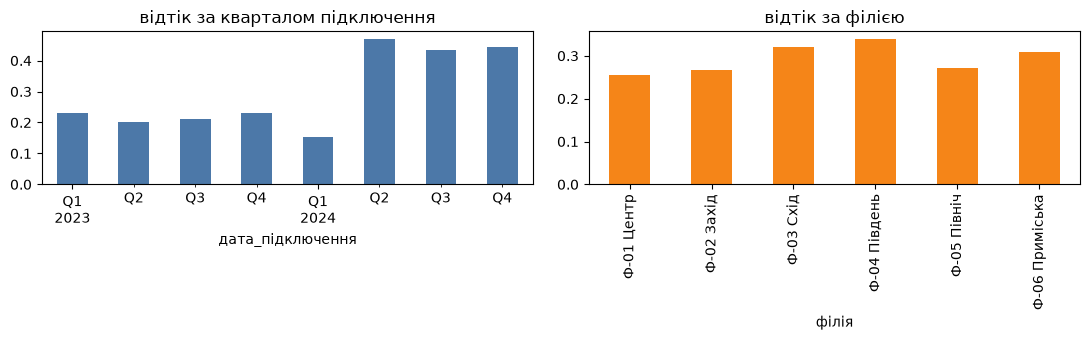

In [19]:
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3)
by_branch.columns = ['частка відтоку', 'клієнтів']
display(by_branch)

dt = pd.to_datetime(raw['дата_підключення'])
by_q = raw.groupby(dt.dt.to_period('Q'))[TARGET].agg(['mean', 'size']).round(3)
by_q.columns = ['частка відтоку', 'клієнтів']
display(by_q)

cands = pd.date_range(dt.min() + pd.Timedelta(days=60), dt.max() - pd.Timedelta(days=60), freq='7D')
sc = [roc_auc_score(y, (dt >= t).astype(int)) for t in cands]
BREAK_DATE = cands[int(np.argmax(sc))]
before = y[dt < BREAK_DATE].mean(); after = y[dt >= BREAK_DATE].mean()
print('найімовірніша дата-злам: %s; частка відтоку до %.3f, після %.3f' % (BREAK_DATE.date(), before, after))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
by_q['частка відтоку'].plot(kind='bar', ax=ax[0], color='#4c78a8'); ax[0].set_title('відтік за кварталом підключення')
by_branch['частка відтоку'].plot(kind='bar', ax=ax[1], color='#f58518'); ax[1].set_title('відтік за філією')
plt.tight_layout(); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'
assert SUSPECT in ('філія', 'дата_підключення')

source = (dt >= BREAK_DATE).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.808
ті самі ознаки передбачають ВІДТІК  : AUC 0.794 ± 0.028


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.985
2. мінус цільовий витік,22,0.924
3. мінус оцінки людини,21,0.817
4. мінус артефакт збору,20,0.794


чесне число: 0.794 ± 0.028


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('частка відтоку стрибає з %.3f до %.3f рівно на даті %s, а бізнес-причини для такої '
                'сходинки немає (плавна зміна була б сезонністю) — схоже на зміну правила обліку; '
                'з датою модель частково вгадує період запису, а не відтік, тому я її викидаю '
                '(AUC відтоку без неї %.3f проти %.3f). Але AUC передбачення джерела за рештою ознак '
                'лишається %.3f: період частково закодований і в інших стовпцях, тож у звіті '
                'модель подається з цим застереженням.'
                % (before, after, BREAK_DATE.date(), auc4.mean(), auc3.mean(), auc_src.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — частка відтоку стрибає з 0.200 до 0.446 рівно на даті 2024-03-07, а бізнес-причини для такої сходинки немає (плавна зміна була б сезонністю) — схоже на зміну правила обліку; з датою модель частково вгадує період запису, а не відтік, тому я її викидаю (AUC відтоку без неї 0.794 проти 0.817). Але AUC передбачення джерела за рештою ознак лишається 0.808: період частково закодований і в інших стовпцях, тож у звіті модель подається з цим застереженням.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=15, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                                   random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05,
                                                           random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    sec = time.time() - t0
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(sec / cv.get_n_splits() * 100, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.794,0.028,10.7
одне дерево,0.737,0.029,4.8
випадковий ліс,0.799,0.028,56.5
гістограмний бустинг,0.788,0.028,70.2


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return float(d.mean()), float(half)


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
PAIRED_MODELS = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    PAIRED_MODELS[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0054 ± 0.0093   у межах шуму
гістограмний бустинг   проти логістичної: -0.0059 ± 0.0076   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'
_rf = PAIRED_MODELS['випадковий ліс']; _hgb = PAIRED_MODELS['гістограмний бустинг']
CHOSEN_WHY = ('за критеріями точності й швидкості: ліс (%+.4f ± %.4f) і бустинг (%+.4f ± %.4f) відносно '
              'логістичної регресії лежать у межах шуму (інтервал накриває нуль), а навчання логістичної '
              'у %.0f разів швидше за ліс (%.1f c проти %.1f c на 100 навчань) і простіше пояснюється; '
              'одне дерево помітно гірше (AUC %.3f). Для розділів 9–11 я все одно беру ліс, бо PDP, '
              'перестановочна важливість і SHAP для дерев показують складніші форми залежностей, а AUC лісу '
              'від логістичної статистично не відрізняється.'
              % (_rf[0], _rf[1], _hgb[0], _hgb[1],
                 cmp_models.loc['випадковий ліс', 'с на 100 навчань'] / cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                 cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                 cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                 cmp_models.loc['одне дерево', 'AUC']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — за критеріями точності й швидкості: ліс (+0.0054 ± 0.0093) і бустинг (-0.0059 ± 0.0076) відносно логістичної регресії лежать у межах шуму (інтервал накриває нуль), а навчання логістичної у 5 разів швидше за ліс (10.7 c проти 56.5 c на 100 навчань) і простіше пояснюється; одне дерево помітно гірше (AUC 0.737). Для розділів 9–11 я все одно беру ліс, бо PDP, перестановочна важливість і SHAP для дерев показують складніші форми залежностей, а AUC лісу від логістичної статистично не відрізняється.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ціна_за_Мбіт: гіпотеза — клієнт, який платить багато за малу швидкість, відчуває переплату й частіше йде
    F['ціна_за_Мбіт'] = (F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']).replace([np.inf, -np.inf], np.nan)
    # звернень_на_місяць: гіпотеза — частота проблем важливіша за їхню кількість за весь час;
    # у новачка 2 звернення за 3 місяці тривожніші, ніж у ветерана 2 за 3 роки
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # платіж_на_послугу: гіпотеза — клієнт із однією дорогою послугою вразливіший, ніж із пакетом із трьох
    F['платіж_на_послугу'] = F['щомісячний_платіж'] / F['кількість_послуг'].clip(lower=1)
    # сумарне_очікування_хв: гіпотеза — біль від підтримки = скільки разів звернувся х скільки чекав;
    # пропуск часу відповіді означає «не звертався», тож очікування = 0
    F['сумарне_очікування_хв'] = (F['середній_час_відповіді_хв'].fillna(0) * F['кількість_звернень_у_підтримку'])
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.792 ± 0.027
приріст проти базового набору: -0.0015 ± 0.0020   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
_t_feat = time.time(); add_features(X4); _t_feat = time.time() - _t_feat
_sig_f = abs(m) > h
_sig_rf = abs(_rf[0]) > _rf[1]
_sig_hgb = abs(_hgb[0]) > _hgb[1]
FEATURES_VS_MODEL = ('Нові ознаки: AUC логістичної %.3f -> %.3f, приріст %+.4f ± %.4f (%s), додаткові витрати часу %.3f c. '
                     'Складніша модель: ліс %+.4f ± %.4f (%s) за %.1f c на 100 навчань проти %.1f c у логістичної; '
                     'бустинг %+.4f ± %.4f (%s). %s'
                     % (base.mean(), auc5.mean(), m, h, 'значущий' if _sig_f else 'у межах шуму', _t_feat,
                        _rf[0], _rf[1], 'значущий' if _sig_rf else 'у межах шуму',
                        cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                        cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                        _hgb[0], _hgb[1], 'значущий' if _sig_hgb else 'у межах шуму',
                        ('Жоден із двох шляхів не дав значущого приросту: гіпотези про переплату, частоту звернень і '
                         'очікування не додали інформації, якої немає в сирих ознаках, а складніша модель лише дорожча.')
                        if not (_sig_f or _sig_rf or _sig_hgb) else
                        'Більше дав шлях: %s.' % ('нові ознаки' if m > max(_rf[0], _hgb[0]) else 'складніша модель')))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Нові ознаки: AUC логістичної 0.794 -> 0.792, приріст -0.0015 ± 0.0020 (у межах шуму), додаткові витрати часу 0.003 c. Складніша модель: ліс +0.0054 ± 0.0093 (у межах шуму) за 56.5 c на 100 навчань проти 10.7 c у логістичної; бустинг -0.0059 ± 0.0076 (у межах шуму). Жоден із двох шляхів не дав значущого приросту: гіпотези про переплату, частоту звернень і очікування не додали інформації, якої немає в сирих ознаках, а складніша модель лише дорожча.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.777
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
щомісячний_платіж,0.0933
код_тарифного_плану,0.0900
ціна_за_Мбіт,0.0789
швидкість_тарифу_Мбіт,0.0717
вік,0.0609
трафік_МБ,0.0592
платіж_на_послугу,0.0547
трафік_ГБ,0.0534
місяців_обслуговування,0.0530
звернень_на_місяць,0.0422


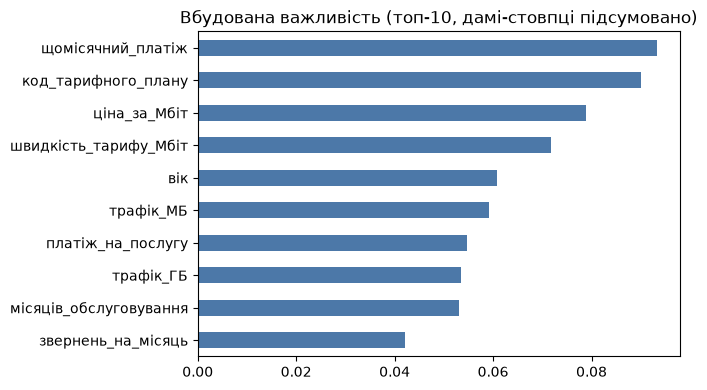

In [30]:
prep = model.named_steps['prep']
names_t = list(prep.get_feature_names_out())

def base_name(fname, cols=list(FINAL_X.columns)):
    rest = fname.split('__', 1)[1]
    hits = [c for c in cols if rest == c or rest.startswith(c + '_')]
    return max(hits, key=len)

gini_raw = pd.Series(model.named_steps['clf'].feature_importances_, index=names_t)
gini_imp = gini_raw.groupby([base_name(n) for n in names_t]).sum().sort_values(ascending=False)
assert abs(gini_imp.sum() - 1) < 1e-6 and set(gini_imp.index) == set(FINAL_X.columns)

display(gini_imp.head(10).to_frame('вбудована важливість').round(4))
ax = gini_imp.head(10)[::-1].plot(kind='barh', figsize=(7, 4), color='#4c78a8')
ax.set_title('Вбудована важливість (топ-10, дамі-стовпці підсумовано)')
plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.041121
швидкість_тарифу_Мбіт,0.024590
трафік_МБ,0.023421
щомісячний_платіж,0.019752
місяців_обслуговування,0.015362
трафік_ГБ,0.011856
кількість_послуг,0.005220
звернень_на_місяць,0.004914
сумарне_очікування_хв,0.004019
платіж_на_послугу,0.003820


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
imp_tbl = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
display(imp_tbl.round(4).head(12))
print('топ-5 за вбудованою важливістю:', list(imp_tbl.index[:5]))
print('їхня перестановочна важливість:', imp_tbl['перестановочна'].iloc[:5].round(4).to_dict())

,вбудована,перестановочна
щомісячний_платіж,0.0933,0.0198
код_тарифного_плану,0.0900,-0.0042
ціна_за_Мбіт,0.0789,0.0038
швидкість_тарифу_Мбіт,0.0717,0.0246
вік,0.0609,0.0411
трафік_МБ,0.0592,0.0234
платіж_на_послугу,0.0547,0.0038
трафік_ГБ,0.0534,0.0119
місяців_обслуговування,0.0530,0.0154
звернень_на_місяць,0.0422,0.0049


топ-5 за вбудованою важливістю: ['щомісячний_платіж', 'код_тарифного_плану', 'ціна_за_Мбіт', 'швидкість_тарифу_Мбіт', 'вік']
їхня перестановочна важливість: {'щомісячний_платіж': 0.0198, 'код_тарифного_плану': -0.0042, 'ціна_за_Мбіт': 0.0038, 'швидкість_тарифу_Мбіт': 0.0246, 'вік': 0.0411}


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'
from scipy.stats import chi2_contingency
_r_g = int(list(gini_imp.index).index(FAKE_IMPORTANT)) + 1
_p_chi = chi2_contingency(pd.crosstab(raw['код_тарифного_плану'], raw[TARGET]))[1]
FAKE_IMPORTANT_WHY = ('вбудована важливість ставить її на %d-те місце (%.3f), а перестановочна на перевірковій частині '
                      'дорівнює %+.4f, тобто модель без неї не гіршає. Це «код» із %d різних значень: для дерева '
                      'кожне з них — окрема дамі-колонка і ще купа можливих розбиттів, тож хоч якесь розбиття '
                      'випадково трохи зменшує неоднорідність на навчальних даних, хоча зв’язку з відтоком '
                      'немає (χ²-тест коду з відтоком: p = %.2f, тобто розбіжності між кодами — шум). Дерево заучує навчальну вибірку, '
                      'а перестановка на нових даних цього не підтверджує.'
                      % (_r_g, gini_imp[FAKE_IMPORTANT], perm_imp[FAKE_IMPORTANT], FINAL_X[FAKE_IMPORTANT].nunique(), _p_chi))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)
print(FAKE_IMPORTANT_WHY)

хибно важлива ознака: код_тарифного_плану
вбудована важливість ставить її на 2-те місце (0.090), а перестановочна на перевірковій частині дорівнює -0.0042, тобто модель без неї не гіршає. Це «код» із 40 різних значень: для дерева кожне з них — окрема дамі-колонка і ще купа можливих розбиттів, тож хоч якесь розбиття випадково трохи зменшує неоднорідність на навчальних даних, хоча зв’язку з відтоком немає (χ²-тест коду з відтоком: p = 0.18, тобто розбіжності між кодами — шум). Дерево заучує навчальну вибірку, а перестановка на нових даних цього не підтверджує.


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
display(pairs.head(5).to_frame('|r|').round(4))

,,|r|
трафік_ГБ,трафік_МБ,0.9997
швидкість_тарифу_Мбіт,щомісячний_платіж,0.7590
середній_час_відповіді_хв,сумарне_очікування_хв,0.7190
кількість_звернень_у_підтримку,сумарне_очікування_хв,0.7109
кількість_послуг,платіж_на_послугу,0.6918


In [35]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

from sklearn.base import clone
drop1 = [DUP_PAIR[1]]
model_nd = make_pipe(FINAL_X.drop(columns=drop1), clone(FINAL_CLF)).fit(Xtr.drop(columns=drop1), ytr)
perm_nd = permutation_importance(model_nd, Xte.drop(columns=drop1), yte, n_repeats=10,
                                 random_state=SEED, scoring='roc_auc')
perm_nd_imp = pd.Series(perm_nd.importances_mean, index=Xte.drop(columns=drop1).columns)
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f   (було %+.4f)' % (DUP_PAIR[0], perm_nd_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[0]]))

drop2 = list(DUP_PAIR)
model_n2 = make_pipe(FINAL_X.drop(columns=drop2), clone(FINAL_CLF)).fit(Xtr.drop(columns=drop2), ytr)
auc_no_one = roc_auc_score(yte, model_nd.predict_proba(Xte.drop(columns=drop1))[:, 1])
auc_no_pair = roc_auc_score(yte, model_n2.predict_proba(Xte.drop(columns=drop2))[:, 1])
print('AUC на відкладеній частині: повна %.3f, без однієї з пари %.3f, без обох %.3f'
      % (auc_hold, auc_no_one, auc_no_pair))

у повній моделі:
   трафік_ГБ                    +0.0119
   трафік_МБ                    +0.0234
без трафік_МБ:
   трафік_ГБ                    +0.0390   (було +0.0119)
AUC на відкладеній частині: повна 0.777, без однієї з пари 0.765, без обох 0.734


In [36]:
DUP_EXPLANATION = ('трафік_ГБ і трафік_МБ — той самий трафік у різних одиницях (|r| = %.4f). У повній моделі '
                   'перестановка однієї колонки лишає інформацію в другій, тому важливість розділилась: ГБ %+.4f, МБ %+.4f, разом %+.4f. '
                   'Коли я прибрав МБ, важливість ГБ зросла до %+.4f — вона забрала на себе роль усієї пари, і її значення '
                   'близьке до суми двох попередніх. AUC на відкладеній частині: повна модель %.3f, без однієї з пари %.3f, '
                   'без обох колонок %.3f. Метод не бреше: він точно відповідає на питання «наскільки гірше буде без ЦІЄЇ '
                   'колонки», а відповідь «небагато» правдива, бо є дублікат; хибний лише висновок «важливість '
                   'колонки мала, отже викидаємо обидві».'
                   % (corr.loc[DUP_PAIR[0], DUP_PAIR[1]], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]],
                      perm_imp[DUP_PAIR[0]] + perm_imp[DUP_PAIR[1]], perm_nd_imp[DUP_PAIR[0]],
                      auc_hold, auc_no_one, auc_no_pair))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_ГБ і трафік_МБ — той самий трафік у різних одиницях (|r| = 0.9997). У повній моделі перестановка однієї колонки лишає інформацію в другій, тому важливість розділилась: ГБ +0.0119, МБ +0.0234, разом +0.0353. Коли я прибрав МБ, важливість ГБ зросла до +0.0390 — вона забрала на себе роль усієї пари, і її значення близьке до суми двох попередніх. AUC на відкладеній частині: повна модель 0.777, без однієї з пари 0.765, без обох колонок 0.734. Метод не бреше: він точно відповідає на питання «наскільки гірше буде без ЦІЄЇ колонки», а відповідь «небагато» правдива, бо є дублікат; хибний лише висновок «важливість колонки мала, отже викидаємо обидві».


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

вік                      (рядків 1200): НЕмонотонна (U-подібна): мінімум 0.270 при 39.72, на краях 0.312 і 0.358
швидкість_тарифу_Мбіт    (рядків 1200): монотонна (зростає): від 0.263 до 0.484
трафік_МБ                (рядків 1200): монотонна (спадає): від 0.366 до 0.266


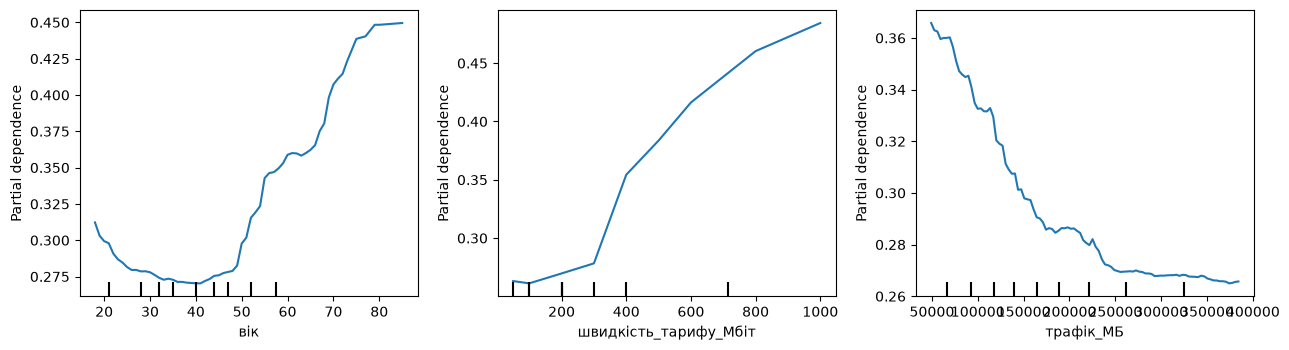

In [37]:
from sklearn.inspection import PartialDependenceDisplay

def pd_shape(grid, avg, edge=0.03):
    """Словесний опис форми PDP: U/∩-подібна, якщо ОБИДВА краї відходять від екстремуму більше ніж на edge."""
    lo, hi = avg.min(), avg.max()
    if avg[0] - lo > edge and avg[-1] - lo > edge:
        return 'НЕмонотонна (U-подібна): мінімум %.3f при %.4g, на краях %.3f і %.3f' % (lo, grid[np.argmin(avg)], avg[0], avg[-1])
    if hi - avg[0] > edge and hi - avg[-1] > edge:
        return 'НЕмонотонна (∩-подібна): максимум %.3f при %.4g, на краях %.3f і %.3f' % (hi, grid[np.argmax(avg)], avg[0], avg[-1])
    return 'монотонна (%s): від %.3f до %.3f' % ('зростає' if avg[-1] > avg[0] else 'спадає', avg[0], avg[-1])

num_only = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category']
top3 = num_only[:3]
PDP_ROWS = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, f in zip(axes, top3):
    sub = FINAL_X[FINAL_X[f].notna()]
    PDP_ROWS[f] = len(sub)
    PartialDependenceDisplay.from_estimator(model, sub, [f], kind='average', ax=ax)
    r = partial_dependence(model, sub, [f], kind='average', grid_resolution=30)
    print('%-24s (рядків %d): %s' % (f, len(sub), pd_shape(r['grid_values'][0], r['average'][0])))
plt.tight_layout(); plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

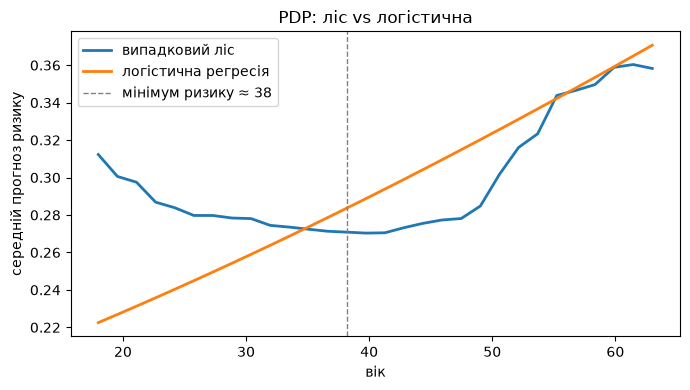

ліс: ризик 0.312 на 18 р., мінімум 0.271 близько 38 р., 0.358 на 63 р.
логістична регресія монотонна: True (від 0.223 до 0.371)


In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
r_rf = partial_dependence(model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=30)
r_lr = partial_dependence(lr_model, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=30)
grid_a, pd_rf, pd_lr = r_rf['grid_values'][0], r_rf['average'][0], r_lr['average'][0]

smooth = np.convolve(pd_rf, np.ones(5) / 5, mode='valid')
x_min = float(grid_a[2:-2][np.argmin(smooth)])
mono_lr = bool(np.all(np.diff(pd_lr) >= -1e-9) or np.all(np.diff(pd_lr) <= 1e-9))

plt.figure(figsize=(7, 4))
plt.plot(grid_a, pd_rf, label='випадковий ліс', lw=2)
plt.plot(grid_a, pd_lr, label='логістична регресія', lw=2)
plt.axvline(x_min, color='gray', ls='--', lw=1, label='мінімум ризику ≈ %.0f' % x_min)
plt.xlabel(NONLINEAR_FEATURE); plt.ylabel('середній прогноз ризику'); plt.legend(); plt.title('PDP: ліс vs логістична')
plt.tight_layout(); plt.show()
print('ліс: ризик %.3f на %d р., мінімум %.3f близько %.0f р., %.3f на %d р.'
      % (pd_rf[0], grid_a[0], smooth.min(), x_min, pd_rf[-1], grid_a[-1]))
print('логістична регресія монотонна: %s (від %.3f до %.3f)' % (mono_lr, pd_lr[0], pd_lr[-1]))

In [39]:
NONLINEAR_MEANING = ('ризик відтоку U-подібний за віком: найнижчий близько %.0f років (%.3f), вищий і для наймолодших '
                     '(%.3f у %d р.), і особливо для літніх (%.3f у %d р.): молодь легко змінює провайдера, літнім '
                     'складніше з технікою й підтримкою. Лінійна модель може лише зростати або лише спадати, '
                     'тому цієї форми не бачить (її PDP монотонна: %s).'
                     % (x_min, smooth.min(), pd_rf[0], grid_a[0], pd_rf[-1], grid_a[-1], mono_lr))
NONLINEAR_FIX = ('додати ознаку «квадрат відхилення віку від %.0f років»: (вік − %.0f)², тоді парабола для '
                 'логістичної регресії стає лінійною за новою ознакою.' % (x_min, x_min))
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик відтоку U-подібний за віком: найнижчий близько 38 років (0.271), вищий і для наймолодших (0.312 у 18 р.), і особливо для літніх (0.358 у 63 р.): молодь легко змінює провайдера, літнім складніше з технікою й підтримкою. Лінійна модель може лише зростати або лише спадати, тому цієї форми не бачить (її PDP монотонна: True).
додати ознаку «квадрат відхилення віку від 38 років»: (вік − 38)², тоді парабола для логістичної регресії стає лінійною за новою ознакою.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
X6 = X5.copy()
X6['вік_відхилення_кв'] = (X6[NONLINEAR_FEATURE] - x_min) ** 2

base5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
auc6 = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m6, h6 = paired(base5, auc6)
print('логістична без ознаки: AUC %.3f ± %.3f' % (base5.mean(), base5.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (auc6.mean(), auc6.std()))
print('приріст %+.4f ± %.4f   %s' % (m6, h6, 'значущий' if abs(m6) > h6 else 'у межах шуму'))

rf_small = lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
a_rf5 = cross_val_score(make_pipe(X5, rf_small()), X5, y, cv=cv, scoring='roc_auc')
a_rf6 = cross_val_score(make_pipe(X6, rf_small()), X6, y, cv=cv, scoring='roc_auc')
m_rf6, h_rf6 = paired(a_rf5, a_rf6)
print('ліс із ознакою проти без: %+.4f ± %.4f   %s' % (m_rf6, h_rf6, 'значущий' if abs(m_rf6) > h_rf6 else 'у межах шуму'))

логістична без ознаки: AUC 0.792 ± 0.027
логістична з ознакою : AUC 0.812 ± 0.029
приріст +0.0200 ± 0.0061   значущий
ліс із ознакою проти без: +0.0081 ± 0.0044   значущий


In [41]:
QUAD_GAIN = m6
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0200


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

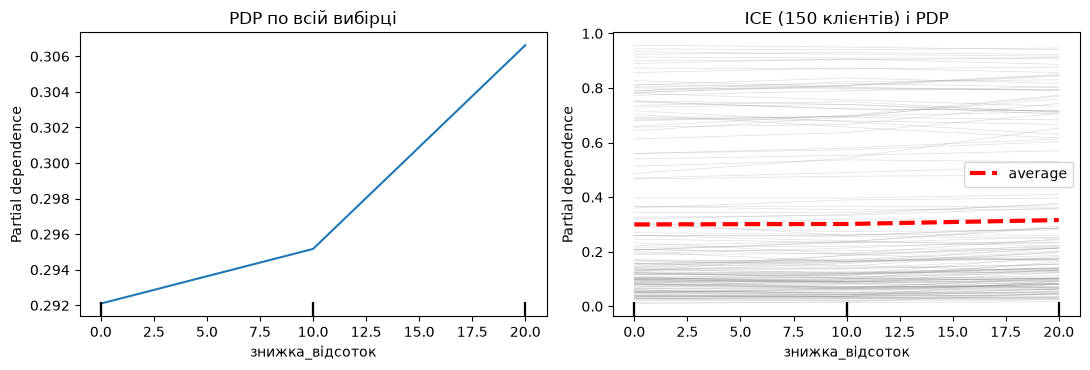

PDP по всій вибірці (знижка [0, 10, 20]): [0.292 0.295 0.307] -> діапазон лише 0.015
ICE: знижка 0 -> 20 % підвищує ризик у 63 % клієнтів і знижує у 32 % (із 1200)
   серед стажу до 24 міс: підвищує у 78 %;  серед стажу понад 24 міс: знижує у 55 %


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
ax[0].set_title('PDP по всій вибірці')
ice_sample = FINAL_X.sample(150, random_state=SEED)
PartialDependenceDisplay.from_estimator(model, ice_sample, ['знижка_відсоток'], kind='both', ax=ax[1],
                                        ice_lines_kw={'alpha': 0.25, 'color': 'gray'},
                                        pd_line_kw={'color': 'red', 'lw': 3})
ax[1].set_title('ICE (150 клієнтів) і PDP')
plt.tight_layout(); plt.show()

r_all = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
PDP_ALL = r_all['average'][0]
print('PDP по всій вибірці (знижка %s): %s -> діапазон лише %.3f' % (
    [int(g) for g in r_all['grid_values'][0]], PDP_ALL.round(3), PDP_ALL.max() - PDP_ALL.min()))

r_ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')
ice = r_ice['individual'][0]
delta = ice[:, -1] - ice[:, 0]
print('ICE: знижка 0 -> 20 %% підвищує ризик у %.0f %% клієнтів і знижує у %.0f %% (із %d)'
      % (100 * (delta > 0).mean(), 100 * (delta < 0).mean(), len(delta)))
long_mask = (FINAL_X['місяців_обслуговування'] > 24).values
print('   серед стажу до 24 міс: підвищує у %.0f %%;  серед стажу понад 24 міс: знижує у %.0f %%'
      % (100 * (delta[~long_mask] > 0).mean(), 100 * (delta[long_mask] < 0).mean()))

стаж до 24 міс     PDP: [0.339 0.348 0.366]
стаж понад 24 міс  PDP: [0.213 0.207 0.207]


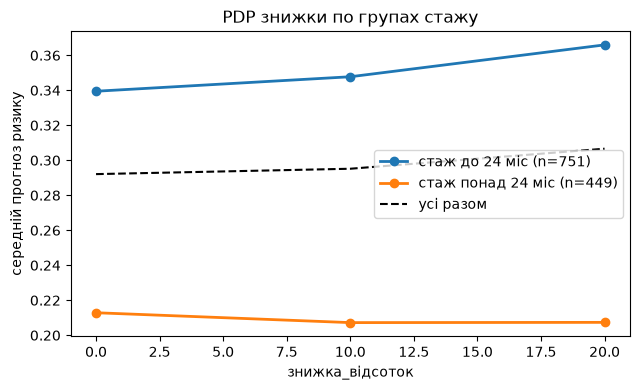

In [43]:
short = (FINAL_X['місяців_обслуговування'] <= 24).values
fig, ax = plt.subplots(figsize=(6.5, 4))
PDP_GROUP = {}
for lab, mk in [('стаж до 24 міс', short), ('стаж понад 24 міс', ~short)]:
    r = partial_dependence(model, FINAL_X[mk], ['знижка_відсоток'], kind='average')
    PDP_GROUP[lab] = r['average'][0]
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2, label='%s (n=%d)' % (lab, mk.sum()))
    print('%-18s PDP: %s' % (lab, r['average'][0].round(3)))
ax.plot(r_all['grid_values'][0], PDP_ALL, 'k--', label='усі разом')
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середній прогноз ризику'); ax.legend()
ax.set_title('PDP знижки по групах стажу'); plt.tight_layout(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
grp = np.where(raw['місяців_обслуговування'] <= 24, 'до 24 міс', 'понад 24 міс')
emp = (raw.assign(стаж=grp).groupby(['стаж', 'знижка_відсоток'])[TARGET].agg(['mean', 'size']))
emp.columns = ['частка відтоку', 'клієнтів']
display(emp.round(3))
EMP = emp['частка відтоку']

частка відтоку  клієнтів
стаж         знижка_відсоток                          
до 24 міс    0                         0.293       311
             10                        0.377       239
             20                        0.438       201
понад 24 міс 0                         0.263       175
             10                        0.162       148
             20                        0.111       126

In [45]:
_s = [EMP[('до 24 міс', k)] for k in (0, 10, 20)]
_l = [EMP[('понад 24 міс', k)] for k in (0, 10, 20)]
INTERACTION_FOUND = ('Знижка діє у різні боки залежно від стажу. До 24 міс частка відтоку ЗРОСТАЄ зі знижкою '
                     '(0/10/20 %%: %.3f -> %.3f -> %.3f), а понад 24 міс СПАДАЄ (%.3f -> %.3f -> %.3f); '
                     'тому PDP по всій вибірці майже плаский (діапазон %.3f), хоча в кожній групі ефект сильний, '
                     'а ICE показує, що криві йдуть у протилежні боки. Модель відтворює НАПРЯМОК обох ефектів, але слабше '
                     'за сиру таблицю (PDP груп: %.3f -> %.3f до 24 міс і %.3f -> %.3f понад 24 міс): у сирій таблиці '
                     'знижка змішана з іншими ознаками (кому її давали), а PDP тримає їх усереднено.'
                     % (*_s, *_l, PDP_ALL.max() - PDP_ALL.min(),
                        PDP_GROUP['стаж до 24 міс'][0], PDP_GROUP['стаж до 24 міс'][-1],
                        PDP_GROUP['стаж понад 24 міс'][0], PDP_GROUP['стаж понад 24 міс'][-1]))
BUSINESS_ACTION = ('Пропонувати знижку слід клієнтам зі стажем понад 24 міс (там її наявність пов’язана з нижчим відтоком), '
                   'а новачкам не роздавати її всім підряд: серед них знижка пов’язана з вищим відтоком. Це кореляція — '
                   'можливо, знижки вже давали тим, хто збирався піти, тож перед зміною політики потрібен A/B-тест.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Знижка діє у різні боки залежно від стажу. До 24 міс частка відтоку ЗРОСТАЄ зі знижкою (0/10/20 %: 0.293 -> 0.377 -> 0.438), а понад 24 міс СПАДАЄ (0.263 -> 0.162 -> 0.111); тому PDP по всій вибірці майже плаский (діапазон 0.015), хоча в кожній групі ефект сильний, а ICE показує, що криві йдуть у протилежні боки. Модель відтворює НАПРЯМОК обох ефектів, але слабше за сиру таблицю (PDP груп: 0.339 -> 0.366 до 24 міс і 0.213 -> 0.207 понад 24 міс): у сирій таблиці знижка змішана з іншими ознаками (кому її давали), а PDP тримає їх усереднено.
Пропонувати знижку слід клієнтам зі стажем понад 24 міс (там її наявність пов’язана з нижчим відтоком), а новачкам не роздавати її всім підряд: серед них знижка пов’язана з вищим відтоком. Це кореляція — можливо, знижки вже давали тим, хто збирався піти, тож перед зміною політики потрібен A/B-тест.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 82)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

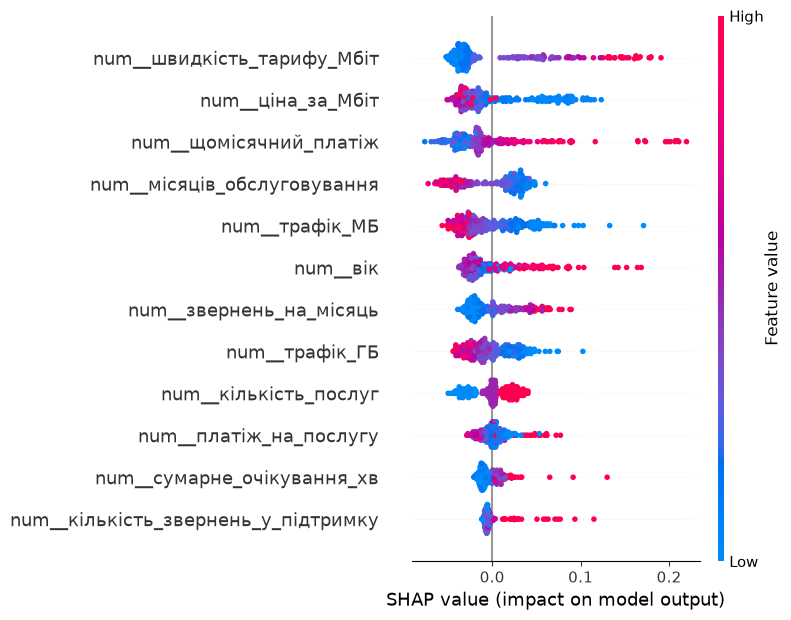

,середній |внесок|
швидкість_тарифу_Мбіт,0.0485
ціна_за_Мбіт,0.0353
щомісячний_платіж,0.0352
місяців_обслуговування,0.0321
код_тарифного_плану,0.0303
трафік_МБ,0.0296
вік,0.0264
звернень_на_місяць,0.0235


In [47]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, show=False, max_display=12)
plt.tight_layout(); plt.show()

shap_by_feat = (pd.Series(np.abs(sv1).mean(0), index=feat_names)
                .groupby([base_name(n) for n in feat_names]).sum().sort_values(ascending=False))
display(shap_by_feat.head(8).to_frame('середній |внесок|').round(4))

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

proba_s = model.predict_proba(Xte)[:SAMPLE, 1]
base_value = float(np.ravel(expl.expected_value)[-1])
row = Xte.iloc[idx]

GROUPS = {
    'вартість і швидкість тарифу': ['щомісячний_платіж', 'швидкість_тарифу_Мбіт', 'ціна_за_Мбіт', 'платіж_на_послугу'],
    'обсяг спожитого трафіку': ['трафік_ГБ', 'трафік_МБ'],
}

contrib = pd.Series(sv1[idx], index=feat_names)
by_feat = contrib.groupby([base_name(n) for n in feat_names]).sum()
grouped = by_feat.copy()
for gname, members in GROUPS.items():
    present = [c for c in members if c in grouped.index]
    grouped = grouped.drop(present)
    grouped[gname] = by_feat[present].sum()
top3_c = grouped.reindex(grouped.abs().sort_values(ascending=False).index)[:3]

for n, v in top3_c.items():
    print('  %-45s внесок %+.3f' % (n, v))
print('базовий рівень %.3f + сума внесків %+.3f = %.3f (прогноз %.3f)'
      % (base_value, contrib.sum(), base_value + contrib.sum(), proba_s[idx]))

ризик клієнта: 0.870
  вартість і швидкість тарифу                   внесок +0.508
  обсяг спожитого трафіку                       внесок +0.039
  місяців_обслуговування                        внесок +0.038
базовий рівень 0.295 + сума внесків +0.575 = 0.870 (прогноз 0.870)


In [49]:
HUMAN = {
    'вік': ('вік клієнта', lambda v: '%d років' % v),
    'стать': ('стать', lambda v: str(v)),
    'місто': ('місто', lambda v: str(v).capitalize()),
    'філія': ('відділення, що обслуговує клієнта', lambda v: str(v).upper()[:1] + str(v)[1:]),
    'тариф': ('тарифний пакет', lambda v: '«%s»' % v),
    'тип_підключення': ('тип підключення', lambda v: str(v)),
    'спосіб_оплати': ('спосіб оплати', lambda v: str(v)),
    'автоплатіж': ('автосписання', lambda v: 'підключене' if v == 'так' else 'не підключене'),
    'кількість_послуг': ('кількість підключених послуг', lambda v: '%d' % v),
    'місяців_обслуговування': ('стаж співпраці', lambda v: '%d міс.' % v),
    'знижка_відсоток': ('діюча знижка', lambda v: '%d %%' % v),
    'кількість_звернень_у_підтримку': ('кількість звернень у підтримку', lambda v: '%d' % v),
    'аварій_на_ділянці_за_квартал': ('аварії на ділянці мережі за квартал', lambda v: '%d' % v),
    'середній_час_відповіді_хв': ('час, за який відповідала підтримка', lambda v: '%.0f хв' % v),
    'код_тарифного_плану': ('код тарифного плану', lambda v: str(v)),
    'скоринг_партнера': ('зовнішній скоринговий бал', lambda v: '%.0f' % v),
    'звернень_на_місяць': ('частота звернень у підтримку', lambda v: '%.2f на місяць' % v),
    'сумарне_очікування_хв': ('сумарний час очікування відповіді підтримки', lambda v: '%.0f хв' % v),
}
GROUP_VIEW = {
    'вартість і швидкість тарифу': lambda r: '%.0f Мбіт/с за %.0f грн на місяць' % (r['швидкість_тарифу_Мбіт'], r['щомісячний_платіж']),
    'обсяг спожитого трафіку': lambda r: '%.0f ГБ за квартал' % (r['трафік_ГБ'] if pd.notna(r['трафік_ГБ']) else r['трафік_МБ'] / 1024),
}

def phrase(n, v):
    if n in GROUP_VIEW:
        label, shown = n, GROUP_VIEW[n](row)
    else:
        label, fmt = HUMAN.get(n, (n.replace('_', ' '), str))
        shown = fmt(row[n]) if pd.notna(row[n]) else 'не відомо'
    return '%s (%s) — %s ризик приблизно на %.0f п. п.' % (label, shown, 'підвищує' if v > 0 else 'знижує', abs(v) * 100)

EXPLANATION_FOR_MANAGER = ('Цей клієнт — серед найризикованіших: ймовірність, що він піде, оцінюється у %.0f %% '
                           '(у середньому по базі — %.0f %%). Найбільше на це впливають: %s. '
                           'Це опис того, чим цей клієнт схожий на тих, хто йшов раніше, а не доказ, що зміна цих '
                           'обставин його втримає.'
                           % (100 * proba_s[idx], 100 * base_value,
                              '; '.join('%d) %s' % (i + 1, phrase(n, v)) for i, (n, v) in enumerate(top3_c.items()))))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей клієнт — серед найризикованіших: ймовірність, що він піде, оцінюється у 87 % (у середньому по базі — 29 %). Найбільше на це впливають: 1) вартість і швидкість тарифу (1000 Мбіт/с за 585 грн на місяць) — підвищує ризик приблизно на 51 п. п.; 2) обсяг спожитого трафіку (129 ГБ за квартал) — підвищує ризик приблизно на 4 п. п.; 3) стаж співпраці (8 міс.) — підвищує ризик приблизно на 4 п. п.. Це опис того, чим цей клієнт схожий на тих, хто йшов раніше, а не доказ, що зміна цих обставин його втримає.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
_rk = list(shap_by_feat.index).index(SHAP_NOT_CAUSAL_FEATURE) + 1
SHAP_NOT_CAUSAL_WHY = ('«вік» має %d-й за величиною внесок за Шеплі (середній |внесок| %.3f), бо ризик залежить від віку '
                       'U-подібно (мінімум близько %.0f років), але вплинути на вік клієнта неможливо: «модель користується '
                       'віком» означає лише, що вік корелює з відтоком (вік відображає покоління, звички, готовність до '
                       'технічних проблем), а не що вік — причина, яку можна змінити. Те саме з «місяців_обслуговування»: '
                       'стаж не можна «змінити» дією відділу утримання.'
                       % (_rk, shap_by_feat[SHAP_NOT_CAUSAL_FEATURE], x_min))
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — «вік» має 7-й за величиною внесок за Шеплі (середній |внесок| 0.026), бо ризик залежить від віку U-подібно (мінімум близько 38 років), але вплинути на вік клієнта неможливо: «модель користується віком» означає лише, що вік корелює з відтоком (вік відображає покоління, звички, готовність до технічних проблем), а не що вік — причина, яку можна змінити. Те саме з «місяців_обслуговування»: стаж не можна «змінити» дією відділу утримання.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
_spd = ['швидкість_тарифу_Мбіт']
_auc_spd = cross_val_score(make_pipe(FINAL_X[_spd], DecisionTreeClassifier(max_depth=3, random_state=SEED)),
                           FINAL_X[_spd], source, cv=cv, scoring='roc_auc').mean()
_fast = raw['швидкість_тарифу_Мбіт'] >= 400
PDP_SPEED_MAX = float(partial_dependence(model, FINAL_X, _spd, kind='average', grid_resolution=30)['average'][0].max())
FIFTH_MISTAKE = ('швидкість_тарифу_Мбіт має %d-ту перестановочну важливість (%.3f) і чіткий PDP (ризик росте до %.2f '
                 'на найшвидших тарифах), але вона ще й кодує артефакт збору: ознаки лише за швидкістю передбачають '
                 'період підключення з AUC %.3f; тарифи від 400 Мбіт/с обрали %.0f %% клієнтів після %s проти %.0f %% до. '
                 'Тож частину «впливу швидкості» дає зміна правила обліку, а не сама швидкість; висновок «знизимо '
                 'швидкість — зменшимо відтік» читати не можна без перевірки по періодах.'
                 % (list(perm_imp.index).index('швидкість_тарифу_Мбіт') + 1, perm_imp['швидкість_тарифу_Мбіт'],
                    PDP_SPEED_MAX, _auc_spd,
                    100 * _fast[source == 1].mean(), BREAK_DATE.date(), 100 * _fast[source == 0].mean()))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

швидкість_тарифу_Мбіт має 2-ту перестановочну важливість (0.025) і чіткий PDP (ризик росте до 0.48 на найшвидших тарифах), але вона ще й кодує артефакт збору: ознаки лише за швидкістю передбачають період підключення з AUC 0.728; тарифи від 400 Мбіт/с обрали 43 % клієнтів після 2024-03-07 проти 19 % до. Тож частину «впливу швидкості» дає зміна правила обліку, а не сама швидкість; висновок «знизимо швидкість — зменшимо відтік» читати не можна без перевірки по періодах.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

TOP_N = 100
p_te = model.predict_proba(Xte)[:, 1]
top_idx_te = np.argsort(-p_te)[:TOP_N]
yte_v = yte.values
top_rate, base_rate = yte_v[top_idx_te].mean(), yte_v.mean()
top_hits = int(yte_v[top_idx_te].sum())
lift = top_rate / base_rate
print('перевіркова частина: %d клієнтів, відтік %.3f; AUC %.3f' % (len(yte_v), base_rate, auc_hold))
print('топ-%d за ризиком: пішло %d (%.3f); навмання очікували б %.1f; lift = %.2f' % (TOP_N, top_hits, top_rate, TOP_N * base_rate, lift))

oof = cross_val_predict(make_pipe(FINAL_X, clone(FINAL_CLF)), FINAL_X, y,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
top_oof = np.argsort(-oof)[:TOP_N]
lift_oof = y.values[top_oof].mean() / y.mean()
print('контроль (прогнози поза навчанням для 1200 клієнтів): топ-%d -> пішло %d (%.3f), lift = %.2f; AUC %.3f'
      % (TOP_N, int(y.values[top_oof].sum()), y.values[top_oof].mean(), lift_oof, roc_auc_score(y, oof)))

перевіркова частина: 360 клієнтів, відтік 0.294; AUC 0.777
топ-100 за ризиком: пішло 56 (0.560); навмання очікували б 29.4; lift = 1.90
контроль (прогнози поза навчанням для 1200 клієнтів): топ-100 -> пішло 81 (0.810), lift = 2.75; AUC 0.803


In [54]:
LIFT_MEANING = ('Серед 100 клієнтів із найвищим ризиком пішло %d (%.0f %%) проти %.0f %% у всій перевірковій частині: '
                'дзвінки за списком влучають у тих, хто піде, у %.2f раза частіше, ніж навмання (контроль на 1200 клієнтах: %.2f).'
                % (top_hits, 100 * top_rate, 100 * base_rate, lift, lift_oof))
assert LIFT_MEANING
print(LIFT_MEANING)

Серед 100 клієнтів із найвищим ризиком пішло 56 (56 %) проти 29 % у всій перевірковій частині: дзвінки за списком влучають у тих, хто піде, у 1.90 раза частіше, ніж навмання (контроль на 1200 клієнтах: 2.75).


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_07.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
_triv = 1 - y.mean()
_m_rf, _h_rf = PAIRED_MODELS['випадковий ліс']
_m_hgb, _h_hgb = PAIRED_MODELS['гістограмний бустинг']
_rk_gini = list(gini_imp.index).index(FAKE_IMPORTANT) + 1
_rk_shap = list(shap_by_feat.index).index(SHAP_NOT_CAUSAL_FEATURE) + 1
_t_lr = cmp_models.loc['логістична регресія', 'с на 100 навчань']
_t_rf = cmp_models.loc['випадковий ліс', 'с на 100 навчань']
_dec = lambda m, h: 'значущий' if abs(m) > h else 'у межах шуму'

REPORT = f'''
1. Метрика — AUC: клас «відтік» складає {y.mean():.1%} клієнтів, тож модель «ніхто не піде» має точність {_triv:.3f} при нульовій користі;
   AUC не залежить від порога й оцінює те, що потрібно відділу утримання, — ранжування клієнтів за ризиком.
2. Викинуто: id_клієнта (технічний ідентифікатор, з'являється при створенні запису); сума_повернення_депозиту (з'являється
   при закритті договору, тобто після відтоку); код_причини_закриття (вказується при закритті, після відтоку);
   кількість_дзвінків_утримання (відділ утримання телефонує вже після того, як побачив ознаки відходу; відтік серед клієнтів
   без дзвінків {raw[raw['кількість_дзвінків_утримання'] == 0][TARGET].mean():.3f}, із дзвінками — {raw[raw['кількість_дзвінків_утримання'] > 0][TARGET].mean():.3f});
   дата_підключення (артефакт збору, сходинка відтоку на {BREAK_DATE.date()}). Детектор не знайшов кількість_дзвінків_утримання:
   поле заповнене в усіх {len(raw)} клієнтів, тому AUC заповненості = 0.5, а проблема в моменті й причині запису, а не в пропусках.
   Дві перші колонки детектор знайшов (показник 1.0, заповнені лише в {int(raw[TARGET].sum())} клієнтів із відтоком).
3. Чесне число: AUC {HONEST_AUC:.3f} ± {auc4.std():.3f} (середнє й розкид із 20 навчань; перший «результат» був {auc_naive.mean():.3f},
   після вилучення цільового витоку {auc2.mean():.3f}, оцінок людини {auc3.mean():.3f}). Розкид {auc4.std():.3f} набагато більший
   за 0.004, тому дві моделі, що відрізняються на 0.004, статистично не розрізняються; для порівняння потрібне парне
   зіставлення: у лісу проти логістичної {_m_rf:+.4f} ± {_h_rf:.4f}.
4. Артефакт збору є: частка відтоку для підключених до {BREAK_DATE.date()} — {before:.3f}, після — {after:.3f}; передбачення джерела
   (підключення після цієї дати) за рештою чесних ознак дає AUC {auc_src.mean():.3f}, тобто період частково закодований
   і в інших ознаках (зокрема у швидкості тарифу). Тому чесне число {HONEST_AUC:.3f} стосується саме цього періоду,
   і переносити модель на іншу філію чи період без перевірки не можна. За філіями сходинки немає
   (відтік {by_branch['частка відтоку'].min():.3f}–{by_branch['частка відтоку'].max():.3f}).
5. Нові ознаки: приріст {auc5.mean() - base.mean():+.4f} ± {paired(base, auc5)[1]:.4f} ({_dec(*paired(base, auc5))}), час майже 0 с.
   Складніша модель: ліс {_m_rf:+.4f} ± {_h_rf:.4f} ({_dec(_m_rf, _h_rf)}), {_t_rf:.1f} c на 100 навчань проти {_t_lr:.1f} c;
   бустинг {_m_hgb:+.4f} ± {_h_hgb:.4f} ({_dec(_m_hgb, _h_hgb)}). Жоден шлях не дав значущого приросту; значущий приріст
   дала лише ознака, прочитана з PDP: {QUAD_GAIN:+.4f} ± {h6:.4f} для логістичної регресії (для лісу {m_rf6:+.4f} ± {h_rf6:.4f}).
6. Помилково важливою вбудована важливість назвала {FAKE_IMPORTANT}: {_rk_gini}-те місце ({gini_imp[FAKE_IMPORTANT]:.3f}),
   а перестановочна на перевірковій частині {perm_imp[FAKE_IMPORTANT]:+.4f}. Ознака має {FINAL_X[FAKE_IMPORTANT].nunique()} рівнів, тож у дерева
   багато можливих розбиттів, і якесь із них випадково зменшує неоднорідність на навчальних даних (зв'язку з відтоком немає, p = {_p_chi:.2f}).
7. Пара {DUP_PAIR[0]} / {DUP_PAIR[1]} (|r| = {corr.loc[DUP_PAIR[0], DUP_PAIR[1]]:.4f}): у повній моделі важливості {perm_imp[DUP_PAIR[0]]:+.4f} і {perm_imp[DUP_PAIR[1]]:+.4f}
   (разом {perm_imp[DUP_PAIR[0]] + perm_imp[DUP_PAIR[1]]:+.4f}); після вилучення {DUP_PAIR[1]} важливість {DUP_PAIR[0]} зросла до {perm_nd_imp[DUP_PAIR[0]]:+.4f},
   тобто забрала на себе роль усієї пари; AUC без однієї з пари {auc_no_one:.3f}, без обох {auc_no_pair:.3f} проти {auc_hold:.3f}.
   Метод не бреше: він відповідає «наскільки гірше без цієї колонки», а інформація є ще й у дублікаті.
8. Немонотонний вплив має {NONLINEAR_FEATURE} (U-подібний, мінімум ризику близько {x_min:.0f} років: {smooth.min():.3f}, на краях {pd_rf[0]:.3f} і {pd_rf[-1]:.3f}).
   Логістична регресія сама його не бачить: її PDP монотонний ({pd_lr[0]:.3f} -> {pd_lr[-1]:.3f}); після додавання (вік − {x_min:.0f})² AUC зріс на {QUAD_GAIN:+.4f}.
   Поріг {x_min:.0f} прочитано з PDP, побудованого на всій вибірці, тому цей приріст трохи оптимістичний.
9. PDP збрехав для знижка_відсоток: по всій вибірці діапазон лише {PDP_ALL.max() - PDP_ALL.min():.3f}, але ICE показує, що ризик зростає у {100 * (delta > 0).mean():.0f} %
   клієнтів і спадає у {100 * (delta < 0).mean():.0f} %; за стажем до 24 міс відтік {EMP[('до 24 міс', 0)]:.3f} -> {EMP[('до 24 міс', 20)]:.3f} при знижці 0 -> 20 %,
   понад 24 міс {EMP[('понад 24 міс', 0)]:.3f} -> {EMP[('понад 24 міс', 20)]:.3f}. У трьох ознак, для яких будувались PDP, пропусків немає,
   тож підвибірка не знадобилась (рядків: {', '.join(str(v) for v in PDP_ROWS.values())}).
10. {SHAP_NOT_CAUSAL_FEATURE}: {_rk_shap}-й за внеском (середній |внесок| {shap_by_feat[SHAP_NOT_CAUSAL_FEATURE]:.3f}), але на вік вплинути не можна: «модель користується»
   ознакою тому, що вона корелює з відтоком, а не тому, що вона його спричиняє.
11. Замовнику: за списком із 100 клієнтів із найвищим ризиком пішло {top_hits} ({top_rate:.0%}) проти {base_rate:.0%} в усій перевірковій частині,
   lift = {lift:.2f} (на прогнозах поза навчанням для всіх 1200 клієнтів {lift_oof:.2f}); AUC {auc_hold:.3f} на відкладеній частині.
   Застереження: оцінка отримана на даних одного періоду зі сходинкою відтоку (AUC джерела {auc_src.mean():.3f}), а розкид AUC ±{auc4.std():.3f}, тому
   реальний lift буде іншим (на 360 клієнтах він шумний), і кореляційні ознаки (швидкість тарифу, знижка) не можна читати як причини; ефект знижки перевіряти A/B-тестом.

Декларація про використання ШІ: для написання коду ноутбука, пошуку витоків, чернеток відповідей і правок після перевірки використано ШІ-асистента Claude (Anthropic).
Самостійно перевірено: запуск згори вниз на чистому ядрі; збіг чисел звіту з виводом ноутбука (звіт будується з тих самих змінних);
чи існує кожен викинутий стовпець у момент прогнозу; що стовпці не викинуто лише за кореляцією з ціллю.
'''
print(REPORT)


1. Метрика — AUC: клас «відтік» складає 29.4% клієнтів, тож модель «ніхто не піде» має точність 0.706 при нульовій користі;
   AUC не залежить від порога й оцінює те, що потрібно відділу утримання, — ранжування клієнтів за ризиком.
2. Викинуто: id_клієнта (технічний ідентифікатор, з'являється при створенні запису); сума_повернення_депозиту (з'являється
   при закритті договору, тобто після відтоку); код_причини_закриття (вказується при закритті, після відтоку);
   кількість_дзвінків_утримання (відділ утримання телефонує вже після того, як побачив ознаки відходу; відтік серед клієнтів
   без дзвінків 0.074, із дзвінками — 0.731);
   дата_підключення (артефакт збору, сходинка відтоку на 2024-03-07). Детектор не знайшов кількість_дзвінків_утримання:
   поле заповнене в усіх 1200 клієнтів, тому AUC заповненості = 0.5, а проблема в моменті й причині запису, а не в пропусках.
   Дві перші колонки детектор знайшов (показник 1.0, заповнені лише в 353 клієнтів із відтоком).
3. Чесне число: AUC

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.